# 제6장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch06


## 6.11 다항 회귀 차수와 훈련·검증 오차

모델 복잡도 변화가 함수 형태와 훈련·검증 오차에 어떤 영향을 주는지 연결한다.

곡선은 같은 훈련 자료로 학습했다. 차수 12가 반드시 과적합한다는 결론을 미리 정하지 않고 실제 검증 오차를 비교한다.

주의: 이 분할은 모델 선택에 쓰는 검증 세트다. 최종 테스트 세트가 아니며 가장 좋은 차수를 고른 뒤의 일반화 성능은 별도 평가해야 한다.

In [2]:
%run sec_11_polynomial_complexity.py

{
  "train_n": 65,
  "validation_n": 35,
  "comparison": [
    {
      "degree": 1,
      "train_mse": 0.5473315381283144,
      "validation_mse": 0.5837276886715528
    },
    {
      "degree": 3,
      "train_mse": 0.09840338772961127,
      "validation_mse": 0.10333037320461691
    },
    {
      "degree": 12,
      "train_mse": 0.0555680496892883,
      "validation_mse": 0.07235448274809285
    }
  ]
}


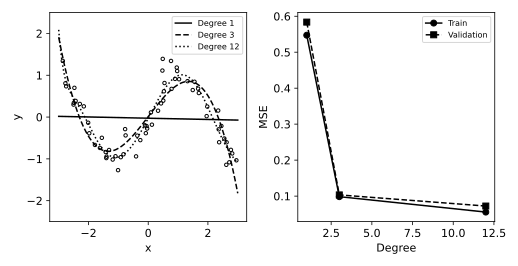

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/polynomial_complexity.svg"))

### 확인 과제

alpha를 0.01, 1, 100으로 바꾸어 정규화가 곡선과 오차에 미치는 영향을 기록한다.

## 6.12 다변량 회귀의 예측·잔차 진단

평가 수치 하나와 예측·잔차의 시각적 진단을 함께 확인한다.

대각선 위쪽은 과대 예측이다. 잔차는 실제값−예측값으로 정의했으므로 오른쪽 양수는 과소 예측을 뜻한다.

주의: 오차의 단위는 원 자료의 price 단위다. 금액 단위가 확인되지 않아 원·만원이라고 임의 표기하지 않는다.

In [4]:
%run sec_12_regression_residual.py

{
  "test_n": 225,
  "MAE": 21262.236678422567,
  "RMSE": 26904.542907001793,
  "R2": 0.8993479315644811
}


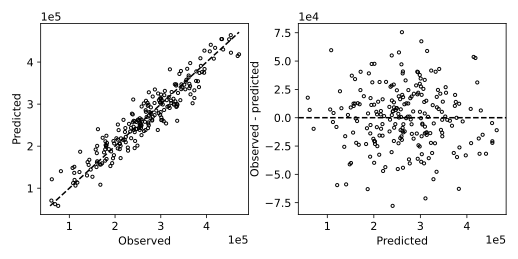

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/regression_residual.svg"))

### 확인 과제

최대 절대 잔차 행을 찾아 입력 특성과 결측을 확인하고 새로운 원인 가설을 2개 쓴다.